(https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/Module6)

Retrieve and search (Appendix C.3–C.4)

Reproduce the book’s retrieval patterns on your table: a filtered SELECT with WHERE, an ORDER BY, and a text search using LIKE with wildcards (for example, every customer whose name contains a chosen letter pair). Finish by pulling one query’s result into pandas and charting it.

In [1]:
import pandas as pd
import sqlite3
conn = sqlite3.connect('customerstable2.db')

In [2]:
query = "SELECT * FROM customers"
df = pd.read_sql_query(query, conn)
df.head(8)

,id,name,city,amount
0,1,Andrew Banner,New York,950.0
1,2,Charlie Danvers,Chicago,75.0
2,3,Ellie Frank,Los Angeles,500.0
3,4,Greg Hauser,Los Angeles,450.0
4,5,Ingrid Jackson,Los Angeles,375.0
5,6,Kevin Lawson,Chicago,100.0
6,7,Michael Newsom,Chicago,80.0
7,8,Otto Pearson,New York,1000.0


In [3]:
query1 = "SELECT * FROM customers WHERE amount > 100"
df1 = pd.read_sql_query(query1, conn)
df1.head(8)

,id,name,city,amount
0,1,Andrew Banner,New York,950.0
1,3,Ellie Frank,Los Angeles,500.0
2,4,Greg Hauser,Los Angeles,450.0
3,5,Ingrid Jackson,Los Angeles,375.0
4,8,Otto Pearson,New York,1000.0


In [4]:
query2 = "SELECT city, AVG(amount) AS avg_amount FROM customers GROUP BY city ORDER BY avg_amount DESC"
df2 = pd.read_sql_query(query2, conn)
df2.head()

,city,avg_amount
0,New York,975.000000
1,Los Angeles,441.666667
2,Chicago,85.000000


In [5]:
query3 = "SELECT * FROM customers WHERE name LIKE '%son%' ORDER BY name DESC"
df3 = pd.read_sql_query(query3, conn)
df3.head()

,id,name,city,amount
0,8,Otto Pearson,New York,1000.0
1,6,Kevin Lawson,Chicago,100.0
2,5,Ingrid Jackson,Los Angeles,375.0


I plotted the second query about the average amount by city.

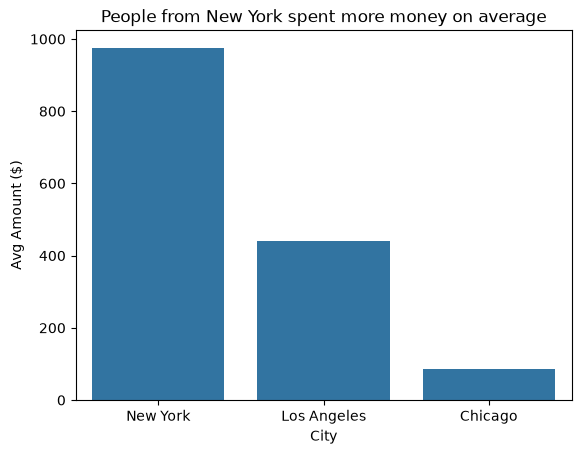

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.barplot(data=df2, x="city", y="avg_amount")
plt.xlabel("City")
plt.ylabel("Avg Amount ($)")
plt.title("People from New York spent more money on average")
plt.show()

In [7]:
conn.close()